# WP09 — Fold PPI kapsamı, küçük encoder ve eğitim öncesi doğrulama

**Yalnız tasarım, gerçek girdi hazırlığı ve encoder mekaniği. GNN eğitimi, loss optimizasyonu, gerçek PT skoru veya performans karşılaştırması yapılmadı.** WP08 B0/B1/B2 sabit referansları korunur. Kaynak kayıt sıralaması klinik yan etki olasılığı değildir; unknown gerçek negatif değildir.

Her fit bağlamında protein evreni yalnız train ilaçlarına bağlı dizi-özellikli accession'lardır. Kesin insan PPI bu evrenin aynı-taxID alt kümesidir. 23 K12/MG1655 koşullu PPI ve özellik eksik80 context yoktur. PPI'sız proteinler self/dizi yolunda kalır. Query ilaçları ve kaynak PT hedefleri eğitim grafına girmez.

In [1]:
from pathlib import Path
import sys,json,re,numpy as np,pandas as pd,matplotlib.pyplot as plt,networkx as nx,torch
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').is_file():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from wp09_encoder import distinguishing_fixture,directed_edges,RoleMaskedPPI
QA=ROOT/'reports/qa/WP09/design_v1';FIG=ROOT/'reports/figures/WP09/design_v1';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',140);pd.set_option('display.max_columns',20);pd.set_option('display.max_colwidth',90)
topology=pd.read_csv(QA/'fold_ppi_topology.csv');coverage=pd.read_csv(QA/'outer_test_PPI_coverage_all62.csv')
quality=pd.read_csv(QA/'shuffle_quality.csv');proposal=json.loads((ROOT/'configs/WP09_training_PROPOSED_v2.json').read_text(encoding='utf-8'))
display(pd.read_csv(QA/'context_inventory.csv'))
display(pd.DataFrame([{'bağlam':topology.context.nunique(),'eşik_senaryosu':len(topology),'train_query_ayrı_NPZ':80,
    'önerilen_eşik':proposal['threshold']['recommended_primary'],'onaylı_eşik':proposal['threshold']['approved_primary'],
    'eğitim_izni':proposal['training_enabled'],'kimya':5,'protein_özelliği':56,'rol':4}]))

,context,train_drugs,train_proteins,query_drugs,query_unseen_sequence_proteins,training_authorized,targets_in_graph
0,primary_o01_final,49,125,13,16,False,False
1,primary_o01_i01,32,92,30,49,False,False
2,primary_o01_i02,33,111,29,30,False,False
3,primary_o01_i03,33,92,29,49,False,False
4,primary_o02_final,49,121,13,20,False,False
5,primary_o02_i01,32,92,30,49,False,False
6,primary_o02_i02,33,106,29,35,False,False
7,primary_o02_i03,33,96,29,45,False,False
8,primary_o03_final,50,133,12,8,False,False
9,primary_o03_i01,33,103,29,38,False,False


,bağlam,eşik_senaryosu,train_query_ayrı_NPZ,önerilen_eşik,onaylı_eşik,eğitim_izni,kimya,protein_özelliği,rol
0,40,120,80,700,None,False,5,56,4


**Yorum:** Ana/stres protokollerinin dış5/iç3 düzeninde toplam40 fit bağlamı vardır; 120 eşik senaryosu bağımsız deney/örnek sayısı değildir. Train-only scaler ve split WP08'den dondurulmuş kaynak olarak kullanıldı, yeniden fit edilmedi. DrugBank5.1 (export2026-01-04), STRINGv12.0 kaynak zinciri korunur; ham büyük dosyalar tekrar taranmadı.

## 1. Her fold gerçekten kaç proteine PPI mesajı sağlar?

,protocol,threshold,human_min,human_max,message_min,message_max,isolates_max,edges_min,edges_max
0,primary,400,37,59,35,58,2,225,559
1,primary,700,37,59,28,48,11,70,178
2,primary,900,37,59,15,35,26,20,78
3,stress,400,35,61,34,59,2,254,564
4,stress,700,35,61,29,49,12,90,176
5,stress,900,35,61,20,34,28,32,76


,context,protocol,outer_fold,inner_fold,threshold,train_drugs,all_sequence_proteins,strict_human_nodes,human_PPI_message_nodes,human_isolates,all_sequence_no_PPI_nodes,undirected_pairs,directed_columns,human_components,human_largest_component,human_density
0,primary_o01_final,primary,1,0,400,49,125,58,56,2,69,510,1020,3,56,0.308530
1,primary_o01_final,primary,1,0,700,49,125,58,48,10,77,173,346,12,46,0.104658
2,primary_o01_final,primary,1,0,900,49,125,58,35,23,90,78,156,28,25,0.047187
3,primary_o01_i01,primary,1,1,400,32,92,49,47,2,45,384,768,3,47,0.326531
4,primary_o01_i01,primary,1,1,700,32,92,49,40,9,52,126,252,11,38,0.107143
5,primary_o01_i01,primary,1,1,900,32,92,49,26,23,66,43,86,27,19,0.036565
6,primary_o01_i02,primary,1,2,400,33,111,51,49,2,62,440,880,3,49,0.345098
7,primary_o01_i02,primary,1,2,700,33,111,51,43,8,68,150,300,10,41,0.117647
8,primary_o01_i02,primary,1,2,900,33,111,51,32,19,79,72,144,24,24,0.056471
9,primary_o01_i03,primary,1,3,400,33,92,43,42,1,50,349,698,2,42,0.386489


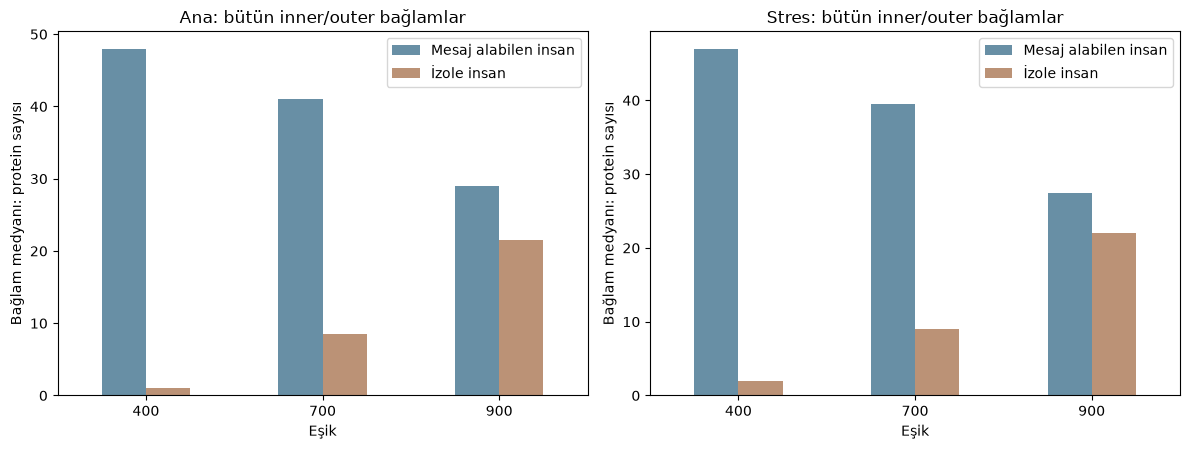

In [2]:
summary=topology.groupby(['protocol','threshold']).agg(human_min=('strict_human_nodes','min'),human_max=('strict_human_nodes','max'),
    message_min=('human_PPI_message_nodes','min'),message_max=('human_PPI_message_nodes','max'),
    isolates_max=('human_isolates','max'),edges_min=('undirected_pairs','min'),edges_max=('undirected_pairs','max')).reset_index()
display(summary);display(topology.drop(columns=['clinical_or_performance_measure']))
fig,axs=plt.subplots(1,2,figsize=(12,4.6))
for ax,protocol,title in zip(axs,['primary','stress'],['Ana: bütün inner/outer bağlamlar','Stres: bütün inner/outer bağlamlar']):
    f=topology[topology.protocol.eq(protocol)].groupby('threshold')[['human_PPI_message_nodes','human_isolates']].median()
    f.rename(columns={'human_PPI_message_nodes':'Mesaj alabilen insan','human_isolates':'İzole insan'}).plot.bar(ax=ax,color=['#688fa5','#bb9276'])
    ax.set(title=title,ylabel='Bağlam medyanı: protein sayısı',xlabel='Eşik');ax.tick_params(axis='x',rotation=0)
plt.tight_layout();plt.savefig(FIG/'01_fold_message_scope.png',dpi=160);plt.show()

**Yorum:** 63 kesin insan accession'ı kaynak evrendir; her train grafında tamamı bulunmaz. 400→700→900 yükseldikçe mesaj alan proteinler azalır ve izoleler artar. Tablolar min/max, grafik bağlam medyanını gösterir; bunlar hata aralığı veya tahmin başarısı değildir. İnsan dışı ve izole proteinler toplam dizi evreninde tutulur. STRING kenarı genel işlevsel ilişki kanıtıdır; doğrudan fiziksel bağ/klinik nedensellik kabul edilmez.

## 2. İlaç ve rol düzeyinde gerçek PPI kapsamı

,protocol,threshold,role,test_drugs,drugs_receiving_PPI,drugs_with_linked_sequence,query_unseen_self_only_relations
0,primary,400,ALL,62,51,60,85
1,primary,400,carrier,62,19,19,3
2,primary,400,enzyme,62,28,38,21
3,primary,400,target,62,15,55,51
4,primary,400,transporter,62,43,43,10
5,primary,700,ALL,62,51,60,85
6,primary,700,carrier,62,19,19,3
7,primary,700,enzyme,62,28,38,21
8,primary,700,target,62,15,55,51
9,primary,700,transporter,62,43,43,10


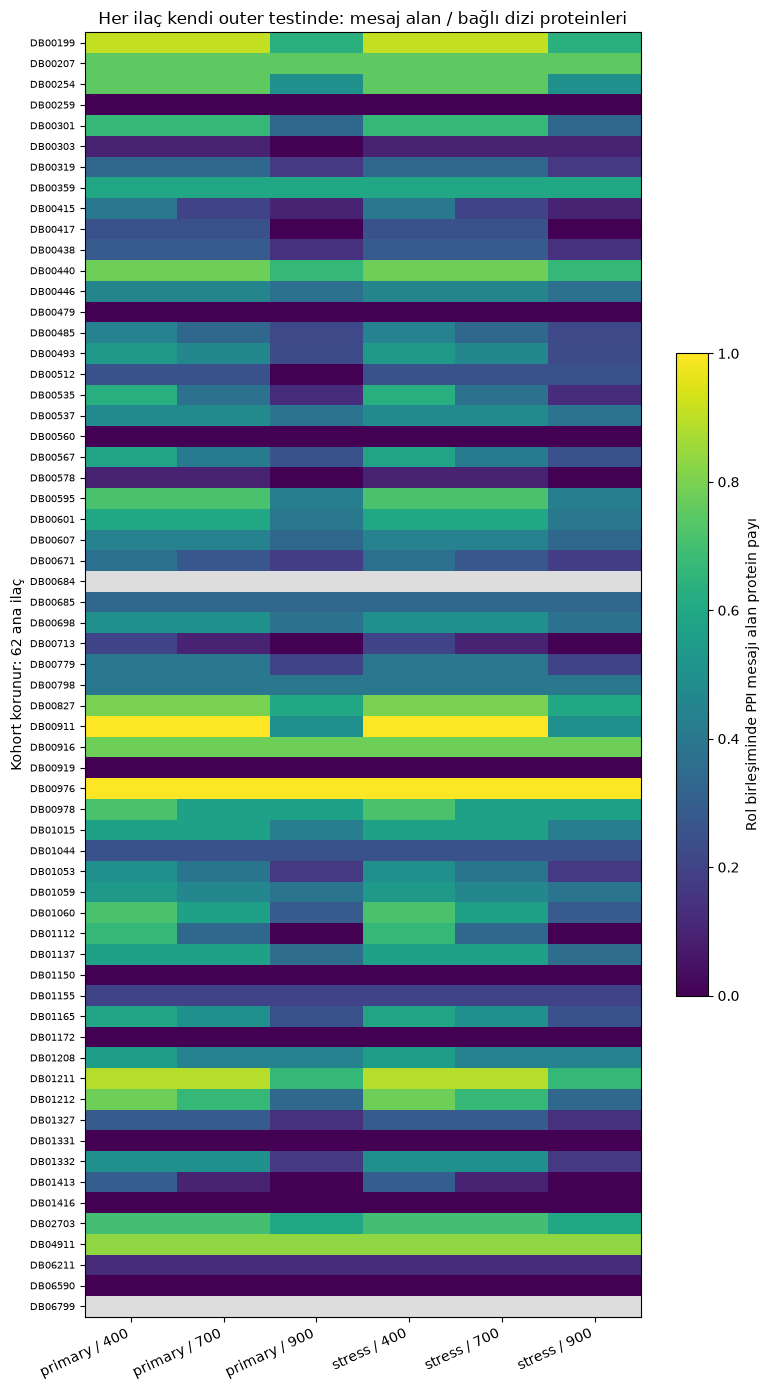

In [3]:
display(coverage)
detail=pd.read_csv(QA/'drug_ppi_coverage.csv')
outer=detail[detail.inner_fold.eq(0)&detail.split.eq('test')&detail.role.eq('ALL')]
heat=outer.pivot(index='drug_id',columns=['protocol','threshold'],values='PPI_message_fraction')
fig,ax=plt.subplots(figsize=(8,14));cmap=plt.get_cmap('viridis').copy();cmap.set_bad('#dddddd')
im=ax.imshow(heat.to_numpy(dtype=float),aspect='auto',vmin=0,vmax=1,cmap=cmap)
ax.set_xticks(range(len(heat.columns)),[f'{p} / {t}' for p,t in heat.columns],rotation=25,ha='right');ax.set_yticks(range(len(heat)),heat.index,fontsize=7)
ax.set(title='Her ilaç kendi outer testinde: mesaj alan / bağlı dizi proteinleri',ylabel='Kohort korunur: 62 ana ilaç')
fig.colorbar(im,ax=ax,label='Rol birleşiminde PPI mesajı alan protein payı',shrink=.5)
plt.tight_layout();plt.savefig(FIG/'02_drug_PPI_coverage.png',dpi=150);plt.show()

**Yorum:** 400 ve700'de her iki protokolde51/62 ilaç en az bir rol üzerinden mesaj erişimi taşır; 900'de ana44/stres46. Bu bir tahmin kapsamı değildir: B2 input uygunluğu61/62, dizi modalitesi60/62 olarak korunur. Ana700'de target rolünde yalnız15 ilaç PPI erişimi taşırken transporter43, enzyme28, carrier19'dur; roller örtüşür ve toplanmaz. İnsan PPI katkısının çoğunu ana antibakteriyel hedef ağı gibi yorumlamamalıyız. Gri hücreler protein modalitesi eksik Tobramycin/Methenamine; protein var ama PPI yoksa değer0'dır.

## 3. Gerçek forward kanıtı: bir kenarı kaldır

,protein,x0,x1,before_h0,before_h1,BC_removed_h0,BC_removed_h1,C_x0_plus2_h0,edge_removal_changes_representation
0,A,1.0,2.0,5.0,5.0,5.0,5.0,5.0,False
1,B,3.0,1.0,7.5,5.0,7.0,4.0,8.5,True
2,C,2.0,4.0,7.0,9.0,4.0,8.0,11.0,True
3,D,5.0,5.0,10.0,10.0,10.0,10.0,10.0,False


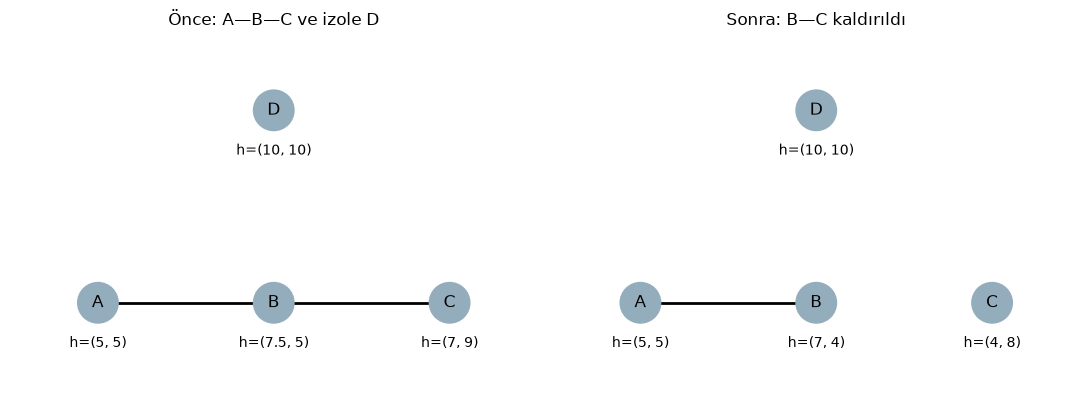

In [4]:
encoder,x,pairs=distinguishing_fixture()
before=encoder(x,directed_edges(pairs));removed=np.array([[0,1]],dtype=np.int64).T
after=encoder(x,directed_edges(removed))
proof=pd.read_csv(QA/'synthetic_forward_proof.csv');display(proof)
fig,axs=plt.subplots(1,2,figsize=(11,4.2));pos={0:(0,0),1:(1,0),2:(2,0),3:(1,1)}
for ax,edges,h,title in zip(axs,[pairs,removed],[before,after],['Önce: A—B—C ve izole D','Sonra: B—C kaldırıldı']):
    g=nx.Graph();g.add_nodes_from(range(4));g.add_edges_from(edges.T.tolist())
    nx.draw_networkx_nodes(g,pos,ax=ax,node_size=850,node_color=['#93adbd']*4)
    nx.draw_networkx_edges(g,pos,ax=ax,width=2)
    nx.draw_networkx_labels(g,pos,labels={i:chr(65+i) for i in range(4)},ax=ax)
    for i in range(4):ax.text(pos[i][0],pos[i][1]-.23,f'h=({h[i,0].item():g}, {h[i,1].item():g})',ha='center',fontsize=10)
    ax.set(title=title,xlim=(-.5,2.5),ylim=(-.5,1.4));ax.axis('off')
plt.tight_layout();plt.savefig(FIG/'03_edge_forward_proof.png',dpi=160);plt.show()

**Yorum:** 56 özellikli gerçek encoder modülünün ilk iki koordinatında ayırt edici, sabit özellik/ağırlıklar kullanıldı. `z=ReLU(Px)`, `h=z+ReLU(Sz+M·mean_neighbors(z))`. B–C kaldırılınca B:(7,5;5)→(7;4), C:(7;9)→(4;8); A ve izoleD değişmez. Böylece edge_index yalnız argüman olarak taşınmıyor, komşu hesabında işleniyor. Her rastgele kenarın her ağırlıkta bütün çıktıları değiştirmesi beklenmez. Bu, öğrenilmiş biyolojik etki değil yazılım mekaniği kanıtıdır.

## 4. Gradient ve mesaj yolu

,output,input_protein,derivative_wrt_x0,interpretation
0,B_h0,A,0.5,one-hop neighbor
1,B_h0,B,2.0,self residual
2,B_h0,C,0.5,one-hop neighbor
3,B_h0,D,0.0,outside receptive field


,çıktı,C_x0_gradient,mesaj_ağırlığı_gradient_normu,optimizer_step
0,B_h0,0.5,3.354102,0


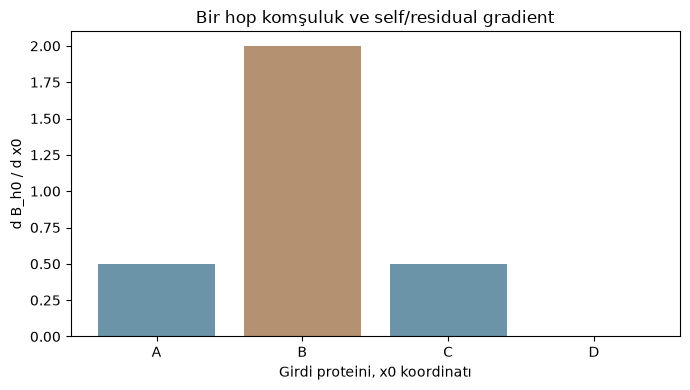

In [5]:
encoder,x,pairs=distinguishing_fixture();x.requires_grad_(True)
encoder(x,directed_edges(pairs))[1,0].backward()
display(pd.read_csv(QA/'synthetic_gradient_proof.csv'))
display(pd.DataFrame([{'çıktı':'B_h0','C_x0_gradient':x.grad[2,0].item(),
    'mesaj_ağırlığı_gradient_normu':encoder.message.weight.grad.norm().item(),'optimizer_step':0}]))
fig,ax=plt.subplots(figsize=(7,4));ax.bar(list('ABCD'),x.grad[:,0].numpy(),color=['#6c94a8','#b49170','#6c94a8','#c4c4c4'])
ax.set(xlabel='Girdi proteini, x0 koordinatı',ylabel='d B_h0 / d x0',title='Bir hop komşuluk ve self/residual gradient')
plt.tight_layout();plt.savefig(FIG/'04_message_gradient.png',dpi=160);plt.show()

**Yorum:** B_h0 için A veC komşu gradienti0,5; B self gradienti2; dış reseptif alandakiD gradienti0. Message katmanı ağırlığına gradient de sıfır değildir. `backward()` yalnız kontrollü türev testi için çalışır; optimizer/adım/öğrenme yoktur. G_noPPI aynı projection/self/readout'u koruyup komşu kenarlarını gerçekten kaldırır.

## 5. Degree-preserving shuffle: başarısız null'u gizleme

,threshold,scenarios,accepted,changed_min,changed_max,degree_exact
0,400,40,0,0.262238,0.425770,True
1,700,40,39,0.485714,0.716867,True
2,900,40,32,0.357143,0.760000,True


,context,threshold,changed_fraction,successful_swaps,status
0,primary_o01_final,400,0.398039,5100,NA_shuffle_insufficient
3,primary_o01_i01,400,0.343750,3840,NA_shuffle_insufficient
6,primary_o01_i02,400,0.354545,4400,NA_shuffle_insufficient
9,primary_o01_i03,400,0.335244,3490,NA_shuffle_insufficient
12,primary_o02_final,400,0.350101,4970,NA_shuffle_insufficient
15,primary_o02_i01,400,0.274834,3020,NA_shuffle_insufficient
17,primary_o02_i01,900,0.452830,530,NA_shuffle_insufficient
18,primary_o02_i02,400,0.340426,4700,NA_shuffle_insufficient
21,primary_o02_i03,400,0.348684,4560,NA_shuffle_insufficient
24,primary_o03_final,400,0.391144,5420,NA_shuffle_insufficient


,bound_min,bound_max,impossibility_proved
threshold,,,
400,0.650350,0.904762,0
700,0.960000,1.000000,0
900,0.928571,1.000000,0


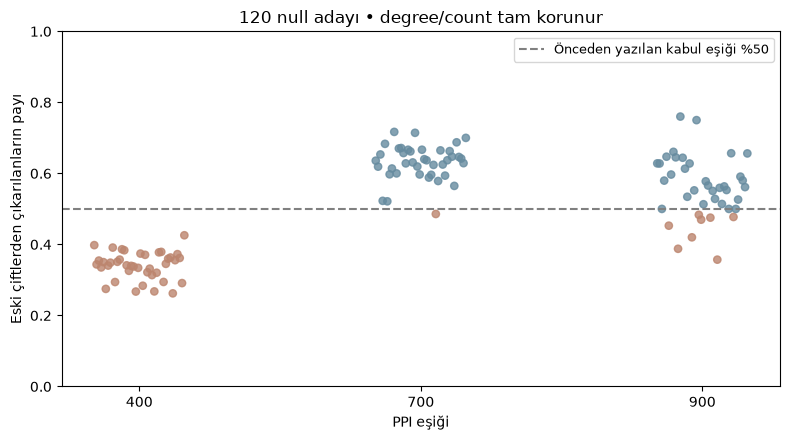

In [6]:
null_summary=quality.groupby('threshold').agg(scenarios=('context','count'),accepted=('status',lambda s:int(s.eq('OK_degree_preserving_null').sum())),
    changed_min=('changed_fraction','min'),changed_max=('changed_fraction','max'),degree_exact=('degree_sequence_exact','all')).reset_index()
display(null_summary);display(quality[quality.status.ne('OK_degree_preserving_null')][['context','threshold','changed_fraction','successful_swaps','status']])
display(pd.read_csv(QA/'shuffle_structural_limits.csv').groupby('threshold').agg(bound_min=('necessary_upper_bound_on_changed_fraction','min'),bound_max=('necessary_upper_bound_on_changed_fraction','max'),impossibility_proved=('raw_50pct_change_mathematically_excluded_by_bound','sum')))
fig,ax=plt.subplots(figsize=(8,4.5))
for i,threshold in enumerate([400,700,900]):
    f=quality[quality.threshold.eq(threshold)];jitter=np.linspace(-.16,.16,len(f))
    ax.scatter(i+jitter,f.changed_fraction,c=np.where(f.status.eq('OK_degree_preserving_null'),'#668b9f','#bc856e'),s=28,alpha=.8)
ax.axhline(.5,color='gray',ls='--',label='Önceden yazılan kabul eşiği %50');ax.set_xticks([0,1,2],[400,700,900]);ax.set(ylim=(0,1),xlabel='PPI eşiği',ylabel='Eski çiftlerden çıkarılanların payı',title='120 null adayı • degree/count tam korunur');ax.legend(fontsize=9)
plt.tight_layout();plt.savefig(FIG/'05_shuffle_quality.png',dpi=160);plt.show()

**Yorum:** Her kenar için10 başarılı swap hedefi, en fazla200 deneme ve değişmiş çift payı≥0,5 kuralı null üretiminden önce kaydedildi. 400:0/40, 700:39/40, 900:32/40 kabul. Başarısız49 aday gerçek kenarla ikame edilmedi; encoder'a verilecek null dosyasında ilgili anahtar yoktur. Derece/kenar sayısı korunması yeterince farklı veya uniform örneklenmiş null garantisi değildir. Hesaplanan gerekli üst sınır hiçbirinde %50 değişimi matematiksel olarak dışlamıyor; algoritmanın bu bütçede başarısızlığı imkânsızlık kanıtı sayılamaz. Kural/seed sonuçlara göre gevşetilmedi.

İlk kapsam-öncelikli400 önerisi v1'de saklandı. Topoloji ve null fizibilitesi sonrasında ayrı **v2 önerisi700** hazırlandı; aynı outer ilaç erişimini daha fazla kullanılabilir null ile korur, fakat bir inner null yetersizdir. Bu bir performans seçimi değildir; onaylı eşik hâlâ `None`.

## 6. Gerçek train insan alt ağı ve kullanılabilir null örneği

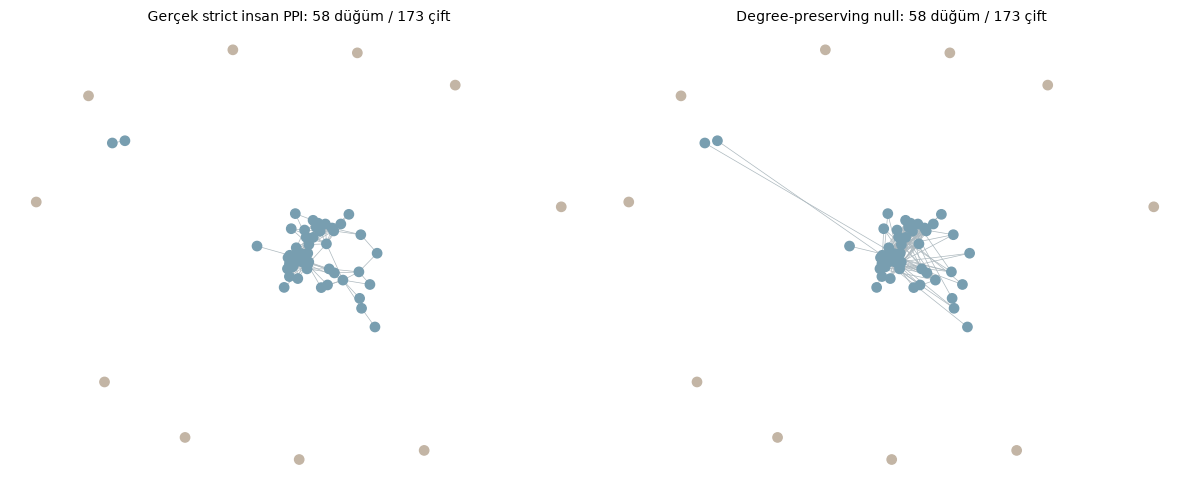

,train_tüm_dizi_proteinleri,bu_çizimde_insan_düğümleri,PPI_dışı_diziler_silinmedi,grafik_koordinatları_biyolojik_uzaklık_değil
0,125,58,True,True


In [7]:
context='primary_o01_final';threshold=700
with np.load(QA/'folds'/(context+'_train.npz'),allow_pickle=False) as archive:graph={k:archive[k] for k in archive.files}
with np.load(QA/'shuffled'/(context+'.npz'),allow_pickle=False) as archive:null=archive['ppi_pairs_700']
mapping=pd.read_csv(ROOT/'reports/qa/WP06/protein_string_mapping.csv');human=set(mapping[mapping.strict_taxon_match&mapping.network_taxid.eq(9606)].accession)
nodes=[i for i,p in enumerate(graph['protein_ids']) if p in human]
real=nx.Graph();real.add_nodes_from(nodes);real.add_edges_from(graph['ppi_pairs_700'].T.tolist());positions=nx.spring_layout(real,seed=20261106)
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,pairs,title in zip(axs,[graph['ppi_pairs_700'],null],['Gerçek strict insan PPI','Degree-preserving null']):
    net=nx.Graph();net.add_nodes_from(nodes);net.add_edges_from(pairs.T.tolist())
    nx.draw_networkx(net,positions,ax=ax,with_labels=False,node_size=45,node_color=['#789eb0' if net.degree(i) else '#c3b5a5' for i in nodes],edge_color='#acb8be',width=.5)
    ax.set_title(f'{title}: {len(nodes)} düğüm / {len(net.edges)} çift',fontsize=10);ax.axis('off')
plt.tight_layout();plt.savefig(FIG/'06_real_vs_shuffled_topology.png',dpi=160);plt.show()
import plotly.graph_objects as go
ex=[];ey=[]
for a,b in real.edges:ex.extend([positions[a][0],positions[b][0],None]);ey.extend([positions[a][1],positions[b][1],None])
interactive=go.Figure([go.Scatter(x=ex,y=ey,mode='lines',line=dict(color='#adb6bf',width=1),hoverinfo='skip'),
    go.Scatter(x=[positions[i][0] for i in nodes],y=[positions[i][1] for i in nodes],mode='markers',
        text=[f'{graph["protein_ids"][i]} | degree={real.degree(i)} | train-only / taxID9606' for i in nodes],
        hoverinfo='text',marker=dict(size=9,color=[real.degree(i) for i in nodes],colorscale='Viridis',showscale=True))])
interactive.update_layout(title='WP09 tasarım • primary_o01_final /700 • gerçek train insan alt ağı',showlegend=False)
interactive.write_html(FIG/'train_human_PPI_interactive.html',include_plotlyjs=True,full_html=True)
display(pd.DataFrame([{'train_tüm_dizi_proteinleri':len(graph['protein_ids']),'bu_çizimde_insan_düğümleri':len(nodes),
    'PPI_dışı_diziler_silinmedi':True,'grafik_koordinatları_biyolojik_uzaklık_değil':True}]))

**Yorum:** Çizim yalnız aynı-taxID insan alt kümesini gösterir; train paketinin diğer dizi proteinleri silinmez. İki grafikte aynı koordinatlar kullanılır; derece korunurken gerçek bağlantılar değişir. Görsel konum biyolojik mesafe değildir. Bu bir topoloji karşılaştırmasıdır, eğitilmiş modellerin performans kıyası değildir. HTML Plotly betiğini içerir; canlı tarayıcı etkileşim testi yapılmadı.

## 7. Küçük mimari ve query güvenlik sınırı

,projection,protein_hidden,PPI_katmanı,kimya_hidden,rol,temsil_boyutu,başlık_hariç_parametre,train_PT_başlık_parametresi,gerçek_veri_PT_başlığı
0,56,32,1,8,4,141,3920,142 × K (train sözlüğü),False


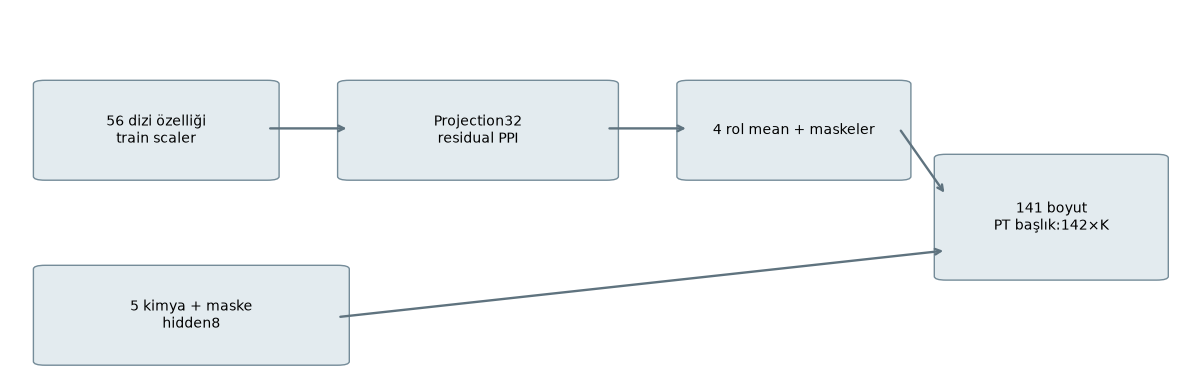

,finite_train,finite_query,cache_unchanged,steps
threshold,,,,
400,True,True,True,0
700,True,True,True,0
900,True,True,True,0


In [8]:
torch.manual_seed(20261106);model=RoleMaskedPPI().double().eval()
display(pd.DataFrame([{'projection':56,'protein_hidden':32,'PPI_katmanı':1,'kimya_hidden':8,'rol':4,
    'temsil_boyutu':model.representation_dim,'başlık_hariç_parametre':sum(p.numel() for p in model.parameters()),
    'train_PT_başlık_parametresi':'142 × K (train sözlüğü)','gerçek_veri_PT_başlığı':model.head is not None}]))
fig,ax=plt.subplots(figsize=(12,4));ax.axis('off')
boxes=[(.03,.55,.19,.25,'56 dizi özelliği / train scaler'),(.29,.55,.22,.25,'Projection32 / residual PPI'),(.58,.55,.18,.25,'4 rol mean + maskeler'),(.03,.05,.25,.25,'5 kimya + maske / hidden8'),(.80,.28,.18,.32,'141 boyut / PT başlık:142×K')]
from matplotlib.patches import FancyBboxPatch
for x0,y0,w,h,label in boxes:ax.add_patch(FancyBboxPatch((x0,y0),w,h,boxstyle='round,pad=.01',facecolor='#e3ebef',edgecolor='#758c99'));ax.text(x0+w/2,y0+h/2,label.replace(' / ',chr(10)),ha='center',va='center',fontsize=10)
for a,b in [((.22,.68),(.29,.68)),((.51,.68),(.58,.68)),((.76,.68),(.80,.5)),((.28,.17),(.80,.35))]:ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',color='#5f737f',lw=1.7))
ax.set(xlim=(0,1),ylim=(0,1));plt.tight_layout();plt.savefig(FIG/'07_small_architecture.png',dpi=160);plt.show()
display(pd.read_csv(QA/'real_encoder_shape_checks.csv').groupby('threshold').agg(finite_train=('finite_train_representations','all'),finite_query=('finite_query_representations','all'),cache_unchanged=('cache_unchanged_after_query','all'),steps=('optimizer_steps','sum')))


**Yorum:** Başlık hariç3920 parametre; train'e özgü K PT için lineer başlık142K parametre ekler. Parametre sayısı küçük denmesine rağmen ~30–50 train ilaçta overfit riski yüksektir; başarı garantisi yoktur. Gerçek veri doğrulamasında başlık kurulmadı ve PT skoru üretilmedi. Üç varyant aynı mimaridir; noPPI'da mesaj yolu kullanılmaz, toplam parametre sayısı aynı olsa da etkin komşu yolu yoktur.

Query ilaç sadece readout alır; cache protein temsiline geri mesaj göndermez. Train evreni dışındaki doğrulanmış query accession'ı aynı frozen scaler/shared self encoder ile PPI'sız işlenir. Query'ler arasında batch normalization veya ortak yeniden-fit yoktur. PPI'sız proteinler korunur; tüm input yoksa abstention, önsel fallback yoktur.

## 8. Test sonucu ve eğitim öncesi karar

In [9]:
text=(QA/'test_results.txt').read_text(encoding='utf-8');match=re.search(r'Ran (\d+) tests in ([\d.]+)s',text)
display(pd.DataFrame([{'otomatik_test':int(match.group(1)),'saniye':float(match.group(2)),
    'tümü_geçti':text.rstrip().endswith('OK'),'eğitim_izni':proposal['training_enabled'],
    'onaylı_PPI_eşiği':proposal['threshold']['approved_primary'],'önerilen_PPI_eşiği':proposal['threshold']['recommended_primary']}]))
display(pd.DataFrame([{'başlık':k,'öneri':str(proposal[k])} for k in ['architecture','optimizer','loss','epochs','seed','shuffle','null_failure_policy']]))
display(pd.DataFrame({'kullanıcı_onayı_bekleyen':proposal['open_gate']}))

,otomatik_test,saniye,tümü_geçti,eğitim_izni,onaylı_PPI_eşiği,önerilen_PPI_eşiği
0,35,7.442,True,False,None,700


,başlık,öneri
0,architecture,"{'protein_features': 56, 'protein_hidden': 32, 'PPI_layers': 1, 'chemistry_hidden': 8,..."
1,optimizer,"{'name': 'AdamW', 'learning_rate': 0.001, 'weight_decay': 0.001}"
2,loss,"{'name': 'BCEWithLogitsLoss', 'reduction': 'mean over valid train targets per eligible..."
3,epochs,"{'maximum': 200, 'inner_early_stopping': 'drug-macro observed-record AP', 'patience': ..."
4,seed,"{'base': 20261106, 'init_formula': 'base + 10000*protocol_index + 100*outer_fold + inn..."
5,shuffle,"{'swaps_per_edge': 10, 'attempts_per_edge': 200, 'minimum_changed_fraction': 0.5, 'see..."
6,null_failure_policy,Keep NA_shuffle_insufficient; never retry seeds or lower 0.5 rule to turn observed fai...


,kullanıcı_onayı_bekleyen
0,primary PPI threshold
1,projection/readout capacity
2,proxy loss and optimizer/LR
3,epoch/early-stop/outer refit policy
4,seed policy
5,shuffle attempts/change threshold/three null replicates
6,accept explicit NA/null failure policy or authorize a separately versioned topology-on...


**Yorum:** Forward/gradient, gerçek kaynak/fold kapsamı, query izolasyonu, derece/sayım ve değişim payı kontrolleri otomatik sınandı. Başarısız null'ların NA tutulması test başarısızlığı değildir; bilimsel sınırlamadır. İlk test geliştirme turlarının logları da saklandı; nihai geçiş sonucu üstte gerçek çalıştırmadan okunur.

Önerilen AdamW/lr0,001/weight_decay0,001, proxy BCE, maksimum200 epoch, inner validation AP patience20 ve outer train için inner epoch medyanı **uygulanmadı**. Null politikası ve bir yetersiz700 inner senaryosu dahil ayrı kullanıcı kararı gerekir. Daha önce görülen WP08 sonuçları nedeniyle gelecekteki kıyas keşifsel kalır; outer test model/eşik seçimine giremez.

[Türkçe rapor](../reports/WP09.md) ve [eğitim öncesi karar kapısı](../reports/WP09_PRETRAINING_DECISION_GATE.md) ayrıntıları sunar. **Tasarım ve encoder doğrulaması tamamlandığında durulur; gerçek GNN eğitimi için ayrı onay gerekir.**